# ANN Clasificación Multiclase — Riesgo Crediticio
Modelo híbrido que combina una ANN binaria preentrenada con un clasificador multiclase
para determinar si un cliente representa un nivel de riesgo **Bajo, Medio, Alto o Crítico**.

## 1. Importación de librerías

In [3]:
# Librerías a utilizar

import os # Permite una interacción con el sistema operativo
import numpy as np # Permite control de arreglos y operaciones matemáticas
import pandas as pd # Permite el manejo de datos
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential # Permite creación de la red por capas
from tensorflow.keras.layers import Dense, Activation, Dropout # Permite a la neurona aprender
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau # Permite la finalización temprana en caso de necesitarlo
from tensorflow.keras.regularizers import l2 # Permite que el modelo le de "mas importancia" a pesos grandes
from tensorflow.keras.models import load_model # Permite cargar el modelo
from sklearn.metrics import classification_report, confusion_matrix # Permite la visualización del desempeño del modelo
from sklearn.metrics import roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

## 2. Carga de datos

In [6]:
base_dir = os.getcwd()
# Permite la obtención de la ruta del script

X_train    = pd.read_csv(os.path.join(base_dir, '../data/processed/X_train_multiclase.csv'))
Y_train    = pd.read_csv(os.path.join(base_dir, '../data/processed/y_train_multiclase.csv'))
X_test     = pd.read_csv(os.path.join(base_dir, '../data/processed/X_test_multiclase.csv'))
Y_test     = pd.read_csv(os.path.join(base_dir, '../data/processed/y_test_multiclase.csv'))
X_train_bi = pd.read_csv(os.path.join(base_dir, '../data/processed/X_train_binario.csv'))
X_test_bi  = pd.read_csv(os.path.join(base_dir, '../data/processed/X_test_binario.csv'))


## 3. Carga del modelo binario preentrenado
Se carga la ANN binaria (bueno/malo) y se inyecta su probabilidad de salida
como columna adicional en los conjuntos de entrenamiento y prueba.

In [8]:
current_dir = os.getcwd()

# Definir la ruta donde guardaste tu modelo binario previamente
ruta_modelo_binario = os.path.abspath(
    os.path.join(current_dir, '../models/modelo_pred_binomial.keras')
)

# Cargar el modelo binario en memoria como un objeto
modelo_binario = load_model(ruta_modelo_binario)
print(f'Modelo binario cargado exitosamente desde: {ruta_modelo_binario}')

Modelo binario cargado exitosamente desde: C:\IA\Proyecto\Proyecto_A_Riesgo_Crediticio\models\modelo_pred_binomial.keras


In [9]:
# Generar la probabilidad binaria para los datos
pred_binaria_train = modelo_binario.predict(X_train_bi)
pred_binaria_test  = modelo_binario.predict(X_test_bi)

# Inyectar la probabilidad como una columna adicional en ambos conjuntos
X_train['prob_binaria'] = pred_binaria_train
X_test['prob_binaria']  = pred_binaria_test

print('X_train con prob_binaria:', X_train.shape)
print('X_test  con prob_binaria:', X_test.shape)

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
X_train con prob_binaria: (800, 63)
X_test  con prob_binaria: (200, 63)


## 4. Definición del modelo multiclase

In [10]:
model = Sequential()
# Definición del modelo

num_neuronas = X_train.shape[1]
# Cantidad de neuronas de entrada

clases_totales = pd.concat([Y_train.squeeze(), Y_test.squeeze()]).unique()
num_neuronas_salida = len(clases_totales)
print('Clases de salida:', num_neuronas_salida)
# Cantidad de neuronas de salida

# Calcular pesos para compensar el desbalance
y_train_array = Y_train.squeeze().to_numpy()
clases_unicas = np.unique(y_train_array)
pesos = compute_class_weight(
    class_weight='balanced', classes=clases_unicas, y=y_train_array
)
class_weights_dict = dict(zip(clases_unicas, pesos))
print('Pesos por clase:', class_weights_dict)

Clases de salida: 4
Pesos por clase: {np.int64(0): np.float64(0.5376344086021505), np.int64(1): np.float64(1.0638297872340425), np.int64(2): np.float64(1.2269938650306749), np.int64(3): np.float64(2.5974025974025974)}


In [11]:
model.add(Dense(units=num_neuronas * 2, kernel_regularizer=l2(0.0001), activation='relu'))
model.add(Dropout(0.3)) # Permite apagar un porcentaje de las neuronas para que encuentre distintas maneras

model.add(Dense(units=num_neuronas, kernel_regularizer=l2(0.0001), activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(units=int(num_neuronas / 2), kernel_regularizer=l2(0.0001), activation='relu'))
model.add(Dropout(0.3))
# Capas ocultas

model.add(Dense(num_neuronas_salida, activation='softmax'))
# Capa de salida múltiple

model.compile(
    loss='sparse_categorical_crossentropy', # "Sparse" se utiliza para cuando son dígitos enteros
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Entrenamiento

In [12]:
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=15, restore_best_weights=True)
reduce_lr  = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=0.0001, verbose=1)
# Permite detenerse antes cuando detecta que el modelo no aprende de manera significativa después de 20 repeticiones

model.fit(
    x=X_train,
    y=Y_train,
    epochs=200,
    batch_size=60,
    validation_split=0.20,
    verbose=1,
    callbacks=[early_stop, reduce_lr],
    class_weight=class_weights_dict
)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.1641 - loss: 1.4214 - val_accuracy: 0.1437 - val_loss: 1.4347 - learning_rate: 5.0000e-04
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1625 - loss: 1.4096 - val_accuracy: 0.2188 - val_loss: 1.4118 - learning_rate: 5.0000e-04
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2234 - loss: 1.3896 - val_accuracy: 0.2438 - val_loss: 1.4010 - learning_rate: 5.0000e-04
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2234 - loss: 1.3757 - val_accuracy: 0.2500 - val_loss: 1.3950 - learning_rate: 5.0000e-04
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2250 - loss: 1.3851 - val_accuracy: 0.2875 - val_loss: 1.3920 - learning_rate: 5.0000e-04
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2234 - loss: 1.3789 - val_accuracy: 0.3250 - val_loss: 1.3834 - learning_rate: 5.0000e-04
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2484

## 6. Curvas de entrenamiento

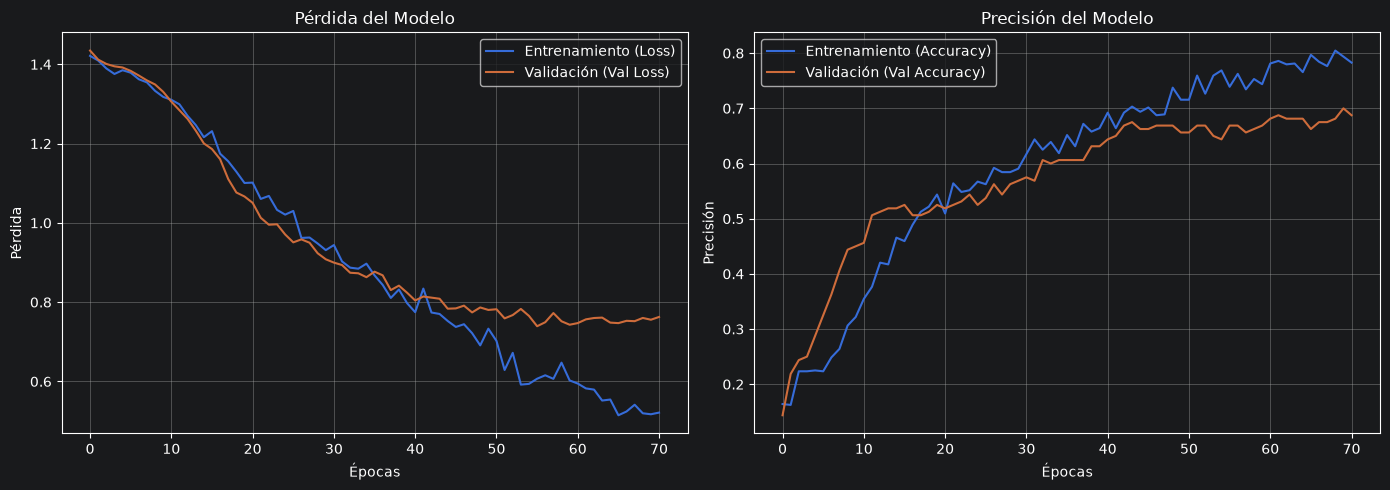

In [13]:
model_loss = pd.DataFrame(model.history.history)
# Convierte el historial a DataFrame

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
# Permite mostrar los dos gráficos juntos

ax[0].plot(model_loss['loss'], label='Entrenamiento (Loss)')
if 'val_loss' in model_loss.columns:
    ax[0].plot(model_loss['val_loss'], label='Validación (Val Loss)')
ax[0].set_title('Pérdida del Modelo')
ax[0].set_xlabel('Épocas')
ax[0].set_ylabel('Pérdida')
ax[0].legend()
ax[0].grid(True)
# Gráfico de Pérdida (Loss)

if 'accuracy' in model_loss.columns:
    ax[1].plot(model_loss['accuracy'], label='Entrenamiento (Accuracy)')
    if 'val_accuracy' in model_loss.columns:
        ax[1].plot(model_loss['val_accuracy'], label='Validación (Val Accuracy)')
    ax[1].set_title('Precisión del Modelo')
    ax[1].set_xlabel('Épocas')
    ax[1].set_ylabel('Precisión')
    ax[1].legend()
    ax[1].grid(True)
# Gráfico de Precisión (Accuracy)

plt.tight_layout()
plt.show()

## 7. Evaluación del modelo
### 7.1. Métricas globales y reporte por clase

In [14]:
nombres_clases = ['Bajo', 'Medio', 'Alto', 'Crítico']
clases = list(range(num_neuronas_salida))
# Permite reemplazar los números por las categorías que se inserten en el arreglo

probabilidades = model.predict(X_test)  # probabilidad por clase (n_muestras x 4)
y_pred = np.argmax(probabilidades, axis=1)  # clase con mayor probabilidad
y_real = Y_test.squeeze().to_numpy() # (n,1) DataFrame -> vector

loss, acc = model.evaluate(X_test, Y_test, verbose=0)
print(f"Loss: {loss:.4f} | Accuracy: {acc:.4f}\n")
# Nos da métricas globales

print(classification_report(y_real, y_pred, labels=clases,
                            target_names=nombres_clases, zero_division=0))
# Genera un reporte por clase (f1, precision, recall)

print(f"ROC-AUC (One-vs-Rest, Macro): {roc_auc_score(y_real, probabilidades, multi_class='ovr', average='macro'):.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
Loss: 0.7403 | Accuracy: 0.7200

              precision    recall  f1-score   support

        Bajo       0.85      0.88      0.86       101
       Medio       0.56      0.46      0.51        39
        Alto       0.57      0.50      0.53        34
     Crítico       0.61      0.77      0.68        26

    accuracy                           0.72       200
   macro avg       0.65      0.65      0.65       200
weighted avg       0.71      0.72      0.71       200

ROC-AUC (One-vs-Rest, Macro): 0.8756


### 7.2. Matrices de confusión

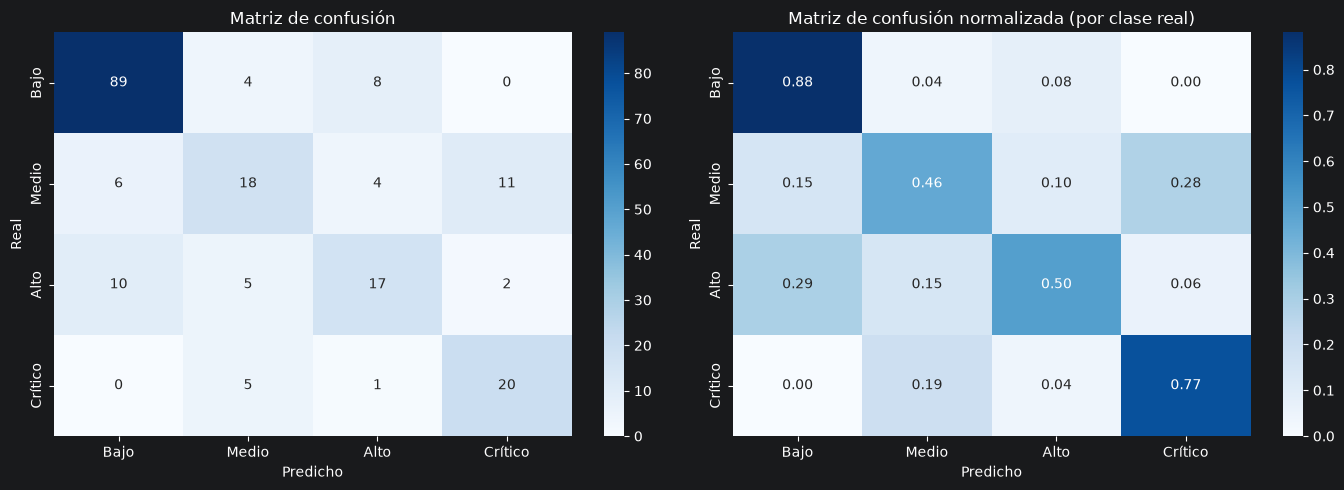

In [15]:
cm = confusion_matrix(y_real, y_pred, labels=clases)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases, yticklabels=nombres_clases, ax=ax[0])
ax[0].set_title('Matriz de confusión')
ax[0].set_xlabel('Predicho')
ax[0].set_ylabel('Real')
# Genera una matriz de confusión con valores absolutos

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=nombres_clases, yticklabels=nombres_clases, ax=ax[1])
ax[1].set_title('Matriz de confusión normalizada (por clase real)')
ax[1].set_xlabel('Predicho')
ax[1].set_ylabel('Real')
plt.tight_layout()
plt.show()
# Genera una matriz de confusión con valores estandarizados

### 7.3. Predicción sobre nuevos datos
Se toman 5 clientes del conjunto de test para simular una predicción en producción.

In [16]:
X_nuevos = X_test.sample(5, random_state=42)   # 5 clientes al azar

prob_nuevos = model.predict(X_nuevos)
resultado   = np.argmax(prob_nuevos, axis=1)

df_resultado = pd.DataFrame({
    'riesgo_predicho': [nombres_clases[i] for i in resultado],
    'confianza':       prob_nuevos.max(axis=1).round(3),
    'riesgo_real':     [nombres_clases[i] for i in Y_test.loc[X_nuevos.index].squeeze()]
}, index=X_nuevos.index)

print(df_resultado)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
    riesgo_predicho  confianza riesgo_real
95            Medio      0.634       Medio
15             Alto      0.481        Alto
30          Crítico      0.651       Medio
158           Medio      0.789     Crítico
128            Alto      0.439       Medio


## 8. Guardar el modelo

In [19]:
carpeta_modelos = os.path.abspath(os.path.join(base_dir, '../models'))
os.makedirs(carpeta_modelos, exist_ok=True)

ruta_modelo = os.path.join(carpeta_modelos, 'modelo_riesgo_multiclase.keras')
model.save(ruta_modelo)
print(f'Modelo guardado en: {ruta_modelo}')

Modelo guardado en: C:\IA\Proyecto\Proyecto_A_Riesgo_Crediticio\models\modelo_riesgo_multiclase.keras
